
# Yambda 11 · Final test results

**Run once, top to bottom.** Every model is retrained on the test split (train < day 287) with the
hyperparameters chosen on validation, and evaluated on days 287–301. Nothing here feeds back into
any modeling decision. SASRec was trained on Colab (`10_test_sasrec_colab.ipynb`); its results are
loaded from `reports/yambda/test_sasrec.json` and `per_user_test_sasrec.parquet`.

Runtime ≈ 25 min (iALS f=512 ~4 min, BPR 18 epochs ~12 min, evaluations).


In [1]:

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import (evaluate, paired_bootstrap, artist_novelty, ArtistLens, known_artist_share)
from musicrec.yambda import load_item_artist
from musicrec.models.baselines import Random, MostPopular
from musicrec.models.als import IALS
from musicrec.models.bpr import BPR

pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.PROJECT_ROOT / "reports" / "yambda"
split = Split.load(config.YAMBDA_SPLIT_TEST_DIR)
targets_all = pd.read_parquet(config.YAMBDA_SPLIT_TEST_DIR / "targets_all.parquet")
item_artist = load_item_artist()
lens = ArtistLens(split, item_artist)
new_artist = artist_novelty(split, item_artist)
print(split.stats)


{'n_users': 8910, 'n_items': 167939, 'train_interactions': 25761645, 'train_pairs': 7783880, 'density': 0.005201958284128993, 'eval_new_pairs_all': 156078, 'eval_new_pairs_reachable': 118034, 'eval_users_with_targets': 6306}


## Models, with hyperparameters fixed on validation

In [2]:

best_ials = json.loads((OUT / "best_ials.json").read_text())
best_bpr = json.loads((OUT / "best_bpr.json").read_text())
VAL_RECALL = {}   # validation recall@10 of the same configuration, for the val-vs-test comparison

models = {
    "Random": Random(),
    "Popular (all time)": MostPopular(by="listeners"),
    "Popular (last 7d)": MostPopular(by="listeners", recent_days=7),
    "iALS (first tuning, nb 04)": IALS(factors=128, regularization=0.05, alpha=10, half_life_days=7),
    "iALS (tuned)": IALS(**best_ials["params"]),
    "BPR (tuned)": BPR(**best_bpr["params"], epochs=best_bpr["best_epoch"], early_stopping=False),
}
VAL_RECALL.update({"Random": 0.0004, "Popular (all time)": 0.0121, "Popular (last 7d)": 0.0235,
                   "iALS (first tuning, nb 04)": 0.0294, "iALS (tuned)": best_ials["val_recall@10"],
                   "BPR (tuned)": best_bpr["val_recall@10"],
                   "SASRec": json.loads((OUT / "best_sasrec.json").read_text())["val"]["recall@10"]})


In [4]:

results, per_user = {}, {}
for name, m in models.items():
    t = time.time()
    m.fit(split) if not isinstance(m, BPR) else m.fit(split, verbose=False)
    r = evaluate(m, split, return_per_user=True)
    per_user[name] = r.pop("per_user")
    r["recall@10 | all targets"] = evaluate(m, split, targets=targets_all)["recall@10"]
    r["recall@10 | known-artist"] = evaluate(m, split, targets=split.targets[~new_artist])["recall@10"]
    r["recall@10 | new-artist"] = evaluate(m, split, targets=split.targets[new_artist])["recall@10"]
    r["known-artist slots in top-10"] = known_artist_share(m, split, lens)
    results[name] = r
    print(f"{name:<30} recall@10={r['recall@10']:.4f}  ({time.time() - t:.0f}s)")

sas = json.loads((OUT / "test_sasrec.json").read_text())
results["SASRec"] = sas["test"]
per_user["SASRec"] = pd.read_parquet(OUT / "per_user_test_sasrec.parquet")


Random                         recall@10=0.0001  (52s)
Popular (all time)             recall@10=0.0137  (176s)
Popular (last 7d)              recall@10=0.0261  (176s)
iALS (first tuning, nb 04)     recall@10=0.0305  (115s)
iALS (tuned)                   recall@10=0.0334  (211s)
BPR (tuned)                    recall@10=0.0327  (367s)


## Final results table (test split)

In [5]:

COLS = ["recall@10", "ndcg@10", "hit_rate@10", "recall@50", "coverage@10", "avg_pop@10",
        "recall@10 | all targets", "recall@10 | known-artist", "recall@10 | new-artist", "known-artist slots in top-10"]
final = pd.DataFrame(results).T[COLS]
final.insert(0, "val recall@10", pd.Series(VAL_RECALL))
final = final.sort_values("recall@10", ascending=False)
final.to_csv(OUT / "final_test_results.csv")
final


,val recall@10,recall@10,ndcg@10,hit_rate@10,recall@50,coverage@10,avg_pop@10,recall@10 | all targets,recall@10 | known-artist,recall@10 | new-artist,known-artist slots in top-10
iALS (tuned),0.0346,0.0334,0.0300,0.1514,0.0661,0.0564,882.0132,0.0831,0.0382,0.0169,0.5678
BPR (tuned),0.0334,0.0327,0.0303,0.1480,0.0581,0.0345,"1,129.0494",0.0700,0.0283,0.0225,0.3923
"iALS (first tuning, nb 04)",0.0294,0.0305,0.0271,0.1419,0.0617,0.0394,"1,074.3934",0.0713,0.0315,0.0174,0.5639
Popular (last 7d),0.0235,0.0261,0.0239,0.1102,0.0424,0.0006,"2,088.5061",0.0373,0.0149,0.0244,0.1641
SASRec,0.0268,0.0227,0.0204,0.1082,0.0459,0.0896,484.8637,0.0534,0.0220,0.0124,0.4680
Popular (all time),0.0121,0.0137,0.0124,0.0614,0.0202,0.0009,"2,954.2378",0.0210,0.0060,0.0134,0.1943
Random,0.0004,0.0001,0.0001,0.0010,0.0002,0.3132,44.3777,0.0003,0.0001,0.0001,0.0645


## Are the differences real? (paired bootstrap over test users)

In [6]:

champ = "iALS (tuned)"
sig = pd.DataFrame({f"{champ} vs {other}": paired_bootstrap(per_user[other], per_user[champ])
                    for other in ["Popular (last 7d)", "iALS (first tuning, nb 04)", "BPR (tuned)", "SASRec"]}).T
sig = sig[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]
sig.to_csv(OUT / "final_test_significance.csv")
sig


,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
iALS (tuned) vs Popular (last 7d),0.0261,0.0334,0.0073,0.2797,0.0039,0.0105,0.0000
"iALS (tuned) vs iALS (first tuning, nb 04)",0.0305,0.0334,0.0029,0.0935,0.0010,0.0048,0.0005
iALS (tuned) vs BPR (tuned),0.0327,0.0334,0.0006,0.0195,-0.0024,0.0035,0.3455
iALS (tuned) vs SASRec,0.0227,0.0334,0.0107,0.4715,0.0080,0.0135,0.0000


In [7]:

# Complementarity of iALS and SASRec on test (the motivation for a two-stage ranker)
m = per_user["iALS (tuned)"].merge(per_user["SASRec"], on="user_idx", suffixes=("_ials", "_sas"))
hi, hs = m["hit_rate@10_ials"] > 0, m["hit_rate@10_sas"] > 0
comp = pd.Series({"hit iALS": hi.mean(), "hit SASRec": hs.mean(), "hit either (oracle)": (hi | hs).mean(),
                  "SASRec only": (hs & ~hi).mean(), "iALS only": (hi & ~hs).mean(),
                  "corr of per-user recall@10": m["recall@10_ials"].corr(m["recall@10_sas"])})
comp.to_csv(OUT / "final_test_complementarity.csv")
comp


hit iALS                     0.1514
hit SASRec                   0.1082
hit either (oracle)          0.2068
SASRec only                  0.0553
iALS only                    0.0986
corr of per-user recall@10   0.3722
dtype: float64

## Figure: test recall@10 with 95% bootstrap intervals

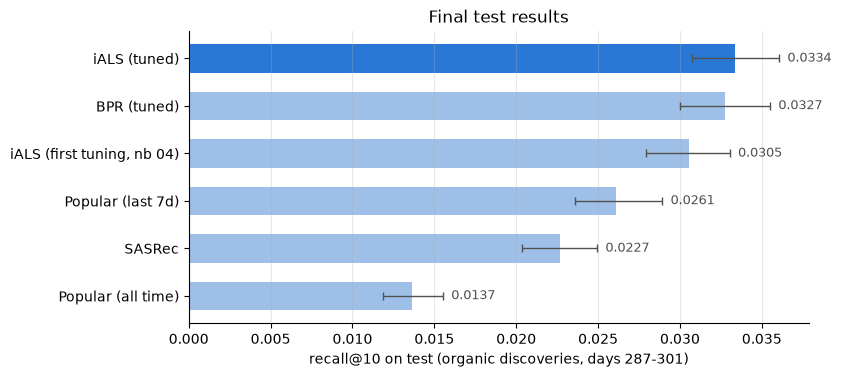

In [9]:

def mean_ci(x, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    b = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n_boot)]
    return x.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

order = [n for n in final.index if n != "Random"][::-1]
stats = [mean_ci(per_user[n]["recall@10"].to_numpy()) for n in order]
BLUE, GRAY = "#2a78d6", "#52514e"
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(order))
means = [s[0] for s in stats]
ax.barh(y, means, color=[BLUE if n == champ else "#9dbfe8" for n in order], height=0.6)
ax.errorbar(means, y, xerr=[[s[0] - s[1] for s in stats], [s[2] - s[0] for s in stats]],
            fmt="none", ecolor=GRAY, capsize=3, lw=1)
for yi, (mval, lo, hi) in zip(y, stats):
    ax.text(hi + 0.0005, yi, f"{mval:.4f}", va="center", color=GRAY, fontsize=9)
ax.set_yticks(y, order)
ax.set(xlabel="recall@10 on test (organic discoveries, days 287-301)", title="Final test results")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y11_final_test.png", dpi=150, bbox_inches="tight")
